# AML Behavioural Risk Analysis and Detection Rules

**Period:** September 2026  
**Snapshot date:** 1 October 2026  
**Tools:** MySQL, Python (pandas, NumPy, Matplotlib, SciPy) and Tableau

I use a synthetic banking dataset to review account behaviour, compare customers with similar profiles and build five simple AML detection rules. The resulting alerts are **investigation leads, not confirmed suspicious activity**.

The notebook reads `feature_snapshot_20261001` from the local MySQL database `aml_behavioural_risk_fe`. Run the SQL feature pipeline first. Then run this notebook from the project folder or its `notebooks` folder.

Install the Python packages once in the VS Code environment:

```bash
pip install pandas numpy matplotlib scipy sqlalchemy mysql-connector-python ipykernel
```

The MySQL password is requested during execution and is not stored in this notebook.

## 1. Load the account snapshot

Connect to the synthetic MySQL database and read the account-level feature snapshot. This step needs your local database to be running.

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Libraries imported.")

Libraries imported.


In [4]:
from sqlalchemy import create_engine, text
from sqlalchemy.engine import URL
from getpass import getpass

# Enter the password when connecting to the local database.
db_password = getpass("MySQL password: ")

db_url = URL.create(
    "mysql+mysqlconnector",
    username="root",
    password=db_password,
    host="127.0.0.1",
    port=3306,
    database="aml_behavioural_risk_fe"
)

engine = create_engine(db_url)

with engine.connect() as conn:
    print("Database:", conn.execute(text("SELECT DATABASE()")).scalar())

Database: aml_behavioural_risk_fe


In [5]:

query = "SELECT * FROM feature_snapshot_20261001"

df = pd.read_sql(query, engine)

print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

df.head()


Rows: 2135
Columns: 51


,account_id,customer_id,customer_type,home_country,account_opened_at,snapshot_date,expected_monthly_txn_count,expected_monthly_turnover_usd,eligible_30d_history,eligible_prior30d_history,...,known_counterparty_txn_count_30d,country_mismatch_count_30d,missing_country_details_30d,actual_customer_txn_count_30d,actual_customer_turnover_30d,actual_customer_inflow_30d,txn_count_vs_expected_ratio_30d,turnover_vs_expected_ratio_30d,txn_velocity_ratio,amount_spike_ratio
0,A00001,C00001,INDIVIDUAL,NL,2025-12-02,2026-10-01,18,1800.0,1,1,...,0,0,0,1,123.80,123.80,0.0556,0.0688,0.0,0.0
1,A00002,C00002,INDIVIDUAL,GB,2025-04-20,2026-10-01,21,8000.0,1,1,...,12,0,0,14,6755.39,3192.47,0.6667,0.8444,0.0,0.0
2,A00003,C00003,INDIVIDUAL,FR,2025-11-27,2026-10-01,12,5500.0,1,1,...,7,0,0,8,4339.14,1699.02,0.6667,0.7889,0.0,0.0
3,A00004,C00004,INDIVIDUAL,GB,2023-10-16,2026-10-01,15,12000.0,1,1,...,5,0,0,7,4257.03,151.19,0.4667,0.3548,0.0,0.0
4,A00005,C00005,INDIVIDUAL,AU,2025-06-07,2026-10-01,11,2500.0,1,1,...,4,0,0,4,1487.73,1050.32,0.3636,0.5951,0.0,0.0


## 2. Check the data before analysing it

I check duplicate accounts, missing ratios and impossible values before using the features in any detection rules. A missing ratio can be expected if the account had no relevant activity.

In [4]:

print("Total records:", len(df))
print("Unique accounts:", df["account_id"].nunique())
print("Duplicate accounts:", df["account_id"].duplicated().sum())


Total records: 2135
Unique accounts: 2135
Duplicate accounts: 0


In [5]:

missing = df.isna().sum()

missing = missing[missing > 0].sort_values(ascending=False)

missing


new_counterparty_share_7d             456
outflow_inflow_ratio_30d              150
top_counterparty_concentration_30d     32
country_mismatch_share_30d             32
cash_amount_share_30d                  25
max_amount_30d                         25
avg_amount_30d                         25
avg_txn_per_active_day_30d             25
txn_velocity_ratio_24h_vs_prior30d     24
amount_spike_ratio_24h_vs_prior30d     24
txn_velocity_ratio                     24
amount_spike_ratio                     24
dtype: int64

In [6]:

no_inflow = df["inflow_amount_30d"] == 0
missing_ratio = df["outflow_inflow_ratio_30d"].isna()

print("Accounts with zero inflow:", no_inflow.sum())
print("Missing outflow/inflow ratios:", missing_ratio.sum())
print("Missing ratios with positive inflow:", (missing_ratio & ~no_inflow).sum())
print("Defined ratios with zero inflow:", (~missing_ratio & no_inflow).sum())


Accounts with zero inflow: 150
Missing outflow/inflow ratios: 150
Missing ratios with positive inflow: 0
Defined ratios with zero inflow: 0


In [7]:

df.dtypes.value_counts()




float64           28
int64             17
str                4
datetime64[us]     1
object             1
Name: count, dtype: int64

In [8]:

print(df.dtypes[df.dtypes == "object"])

df["snapshot_date"] = pd.to_datetime(df["snapshot_date"])

print(df["snapshot_date"].dtype)
print(df["snapshot_date"].nunique())


snapshot_date    object
dtype: object
datetime64[s]
1


In [9]:

count_cols = [
    "txn_count_24h",
    "txn_count_7d",
    "txn_count_30d",
    "active_days_30d",
    "unique_counterparties_7d",
    "unique_counterparties_30d"
]

negative_counts = (df[count_cols] < 0).sum().sum()

invalid_txn_windows = (
    (df["txn_count_24h"] > df["txn_count_7d"]) |
    (df["txn_count_7d"] > df["txn_count_30d"])
).sum()

invalid_active_days = (
    (df["active_days_30d"] > 30) |
    (df["active_days_30d"] > df["txn_count_30d"])
).sum()

invalid_counterparty_counts = (
    (df["unique_counterparties_7d"] > df["txn_count_7d"]) |
    (df["unique_counterparties_30d"] > df["txn_count_30d"])
).sum()

print("Negative counts:", negative_counts)
print("Invalid transaction windows:", invalid_txn_windows)
print("Invalid active days:", invalid_active_days)
print("Invalid counterparty counts:", invalid_counterparty_counts)


Negative counts: 0
Invalid transaction windows: 0
Invalid active days: 0
Invalid counterparty counts: 0


In [10]:

amount_cols = [
    "amount_total_24h",
    "amount_total_7d",
    "amount_total_30d",
    "inflow_amount_30d",
    "outflow_amount_30d",
    "cash_amount_30d"
]

negative_amounts = (df[amount_cols] < 0).sum().sum()

invalid_amount_windows = (
    (df["amount_total_24h"] > df["amount_total_7d"]) |
    (df["amount_total_7d"] > df["amount_total_30d"])
).sum()

flow_difference = (
    df["inflow_amount_30d"] +
    df["outflow_amount_30d"] -
    df["amount_total_30d"]
).abs()

invalid_flow_totals = (flow_difference > 0.01).sum()

ratio_cols = [
    "cash_amount_share_30d",
    "new_counterparty_share_7d",
    "top_counterparty_concentration_30d",
    "country_mismatch_share_30d"
]

invalid_ratios = (
    (df[ratio_cols] < 0) |
    (df[ratio_cols] > 1)
).sum().sum()

print("Negative amounts:", negative_amounts)
print("Invalid amount windows:", invalid_amount_windows)
print("Invalid flow totals:", invalid_flow_totals)
print("Invalid proportion ratios:", invalid_ratios)


Negative amounts: 0
Invalid amount windows: 0
Invalid flow totals: 0
Invalid proportion ratios: 0


## 3. Reconcile SQL and Python totals

The transaction count and turnover in the snapshot should match the September transactions in MySQL. Then I look at the size and spread of the activity.

In [11]:

query = """
SELECT
    COUNT(*) AS total_transactions,
    ROUND(SUM(amount_usd), 2) AS total_amount
FROM transactions
WHERE occurred_at >= '2026-09-01'
  AND occurred_at < '2026-10-01'
  AND posted_at < '2026-10-01'
"""

db_totals = pd.read_sql(query, engine).iloc[0]

python_txns = df["txn_count_30d"].sum()
python_amount = round(df["amount_total_30d"].sum(), 2)

print("Python transactions:", python_txns)
print("MySQL transactions:", db_totals["total_transactions"])

print("Python amount:", python_amount)
print("MySQL amount:", db_totals["total_amount"])

print("Transaction counts match:",
      python_txns == db_totals["total_transactions"])

print("Amounts match:",
      np.isclose(python_amount, db_totals["total_amount"], atol=0.01, rtol=0))


Python transactions: 18846
MySQL transactions: 18846.0
Python amount: 27315157.3
MySQL amount: 27315157.3
Transaction counts match: True
Amounts match: True


In [12]:

cols = ["txn_count_30d", "amount_total_30d"]

df[cols].describe(
    percentiles=[0.50, 0.90, 0.95, 0.99]
).T


,count,mean,std,min,50%,90%,95%,99%,max
txn_count_30d,2135.0,8.827166,5.037778,0.0,8.00,15.000,17.000,24.0000,85.00
amount_total_30d,2135.0,12793.984684,27939.008448,0.0,3893.13,29153.642,57288.323,149552.8948,342967.31


## 4. Compare customer groups and review a case

Business and individual accounts have different activity patterns, so I calculate peer-group benchmarks rather than applying one amount threshold to every account. I also review customer `C01598` as a sample case.

In [13]:

customer_summary = (
    df.groupby("customer_type")
    .agg(
        accounts=("account_id", "count"),
        avg_txns=("txn_count_30d", "mean"),
        median_txns=("txn_count_30d", "median"),
        avg_amount=("amount_total_30d", "mean"),
        median_amount=("amount_total_30d", "median")
    )
    .round(2)
)

customer_summary


,accounts,avg_txns,median_txns,avg_amount,median_amount
customer_type,,,,,
BUSINESS,454,13.21,13.0,40899.34,24119.16
INDIVIDUAL,1681,7.64,7.0,5203.37,2732.18


In [14]:

cols = ["txn_count_30d", "amount_total_30d"]

peer_percentiles = (
    df.groupby("customer_type")[cols]
    .quantile([0.90, 0.95, 0.99])
    .round(2)
)

peer_percentiles


txn_count_30d  amount_total_30d
customer_type                                      
BUSINESS      0.90          20.00          99670.88
              0.95          23.00         148275.62
              0.99          29.47         199231.67
INDIVIDUAL    0.90          12.00          10925.50
              0.95          14.00          15133.17
              0.99          19.00          29339.71

In [15]:

peer_limits = df.groupby("customer_type")["amount_total_30d"].quantile(0.95)

df["peer_p95_amount"] = df["customer_type"].map(peer_limits)

df["high_turnover_flag"] = (
    df["amount_total_30d"] > df["peer_p95_amount"]
)

df.groupby("customer_type")["high_turnover_flag"].sum()


customer_type
BUSINESS      23
INDIVIDUAL    84
Name: high_turnover_flag, dtype: int64

In [16]:

flagged_accounts = df.loc[
    df["high_turnover_flag"],
    [
        "account_id",
        "customer_type",
        "txn_count_30d",
        "amount_total_30d",
        "peer_p95_amount",
        "expected_count_ratio_30d",
        "inflow_vs_expected_turnover_ratio_30d"
    ]
]

flagged_accounts.sort_values(
    "amount_total_30d", ascending=False
).head(10).round(2)


,account_id,customer_type,txn_count_30d,amount_total_30d,peer_p95_amount,expected_count_ratio_30d,inflow_vs_expected_turnover_ratio_30d
2004,A02005,INDIVIDUAL,18,342967.31,15133.17,2.00,49.91
1580,A01581,BUSINESS,28,330611.53,148275.62,1.87,0.86
269,A00270,BUSINESS,23,266260.59,148275.62,1.44,0.84
270,A00271,BUSINESS,16,239497.07,148275.62,1.44,0.84
105,A00106,BUSINESS,14,234745.17,148275.62,0.88,0.46
1040,A01041,BUSINESS,19,202863.38,148275.62,0.76,0.60
191,A00192,BUSINESS,12,196011.09,148275.62,0.52,0.69
1504,A01505,BUSINESS,30,195616.76,148275.62,1.18,0.64
863,A00864,BUSINESS,24,191733.51,148275.62,1.22,0.39
609,A00610,BUSINESS,19,188027.21,148275.62,0.70,0.18


In [17]:

cols = [
    "account_id",
    "customer_id",
    "customer_type",
    "txn_count_30d",
    "amount_total_30d",
    "inflow_amount_30d",
    "outflow_amount_30d",
    "cash_amount_share_30d",
    "unique_counterparties_30d",
    "country_mismatch_share_30d",
    "expected_count_ratio_30d",
    "inflow_vs_expected_turnover_ratio_30d",
    "dormant_reactivation_flag_24h"
]

df.loc[df["account_id"] == "A02005", cols].T


,2004
account_id,A02005
customer_id,C01598
customer_type,INDIVIDUAL
txn_count_30d,18
amount_total_30d,342967.31
inflow_amount_30d,124432.4
outflow_amount_30d,218534.91
cash_amount_share_30d,0.0003
unique_counterparties_30d,16
country_mismatch_share_30d,0.0


In [18]:

customer_accounts = df.loc[
    df["customer_id"] == "C01598",
    [
        "account_id",
        "customer_id",
        "txn_count_30d",
        "amount_total_30d",
        "inflow_amount_30d",
        "outflow_amount_30d",
        "expected_count_ratio_30d",
        "inflow_vs_expected_turnover_ratio_30d"
    ]
]

print("Total linked accounts:", len(customer_accounts))

customer_accounts.round(2)


Total linked accounts: 2


,account_id,customer_id,txn_count_30d,amount_total_30d,inflow_amount_30d,outflow_amount_30d,expected_count_ratio_30d,inflow_vs_expected_turnover_ratio_30d
2004,A02005,C01598,18,342967.31,124432.4,218534.91,2.0,49.91
2005,A02006,C01598,8,966.79,350.1,616.69,2.0,49.91


In [19]:

case_summary = (
    df[df["customer_id"] == "C01598"]
    .groupby("customer_id")
    .agg(
        total_accounts=("account_id", "nunique"),
        total_txns=("txn_count_30d", "sum"),
        total_turnover=("amount_total_30d", "sum"),
        total_inflow=("inflow_amount_30d", "sum"),
        total_outflow=("outflow_amount_30d", "sum"),
        expected_count_ratio=("expected_count_ratio_30d", "first"),
        expected_inflow_ratio=("inflow_vs_expected_turnover_ratio_30d", "first")
    )
    .round(2)
)

case_summary


,total_accounts,total_txns,total_turnover,total_inflow,total_outflow,expected_count_ratio,expected_inflow_ratio
customer_id,,,,,,,
C01598,2,26,343934.1,124782.5,219151.6,2.0,49.91


## 5. Explore the behaviour visually

These charts make the turnover, transaction frequency and counterparty patterns easier to inspect. High values are leads for review, not proof of wrongdoing.

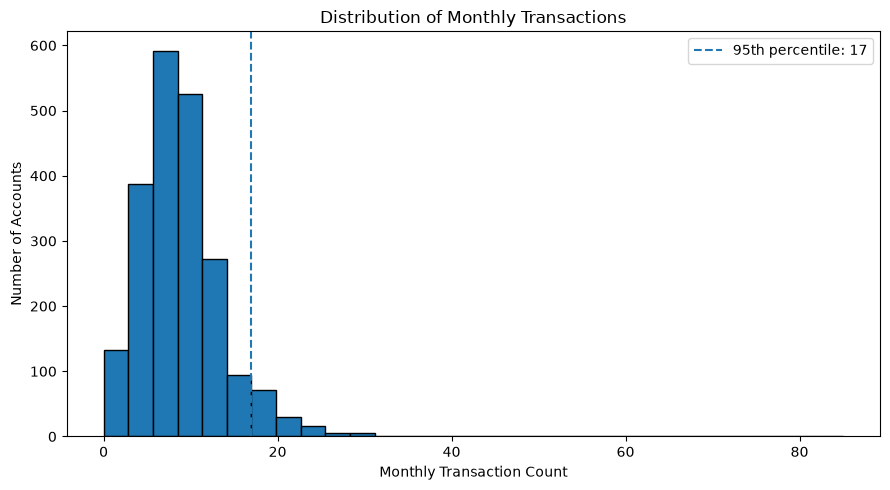

In [20]:

import matplotlib.pyplot as plt

p95 = df["txn_count_30d"].quantile(0.95)

plt.figure(figsize=(9, 5))

plt.hist(df["txn_count_30d"], bins=30, edgecolor="black")

plt.axvline(
    p95,
    linestyle="--",
    label=f"95th percentile: {p95:.0f}"
)

plt.xlabel("Monthly Transaction Count")
plt.ylabel("Number of Accounts")
plt.title("Distribution of Monthly Transactions")

plt.legend()
plt.tight_layout()
plt.show()


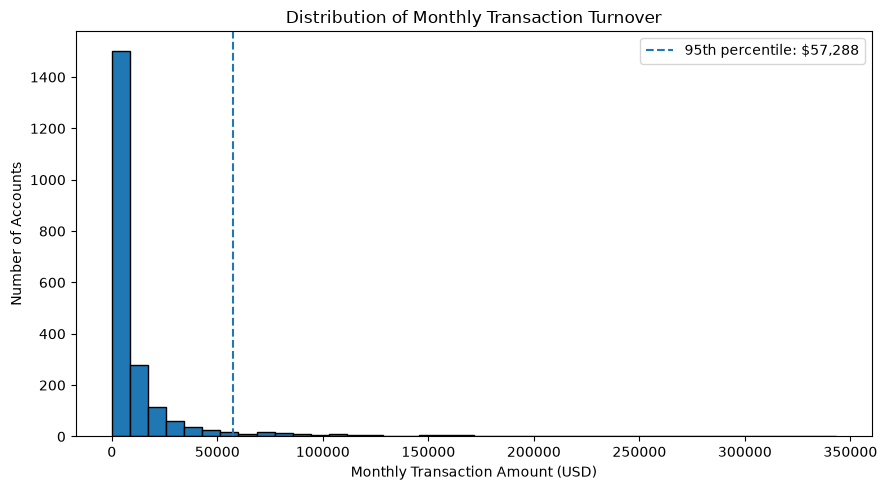

In [21]:

p95_amount = df["amount_total_30d"].quantile(0.95)

plt.figure(figsize=(9, 5))

plt.hist(
    df["amount_total_30d"],
    bins=40,
    edgecolor="black"
)

plt.axvline(
    p95_amount,
    linestyle="--",
    label=f"95th percentile: ${p95_amount:,.0f}"
)

plt.xlabel("Monthly Transaction Amount (USD)")
plt.ylabel("Number of Accounts")
plt.title("Distribution of Monthly Transaction Turnover")

plt.legend()
plt.tight_layout()
plt.show()


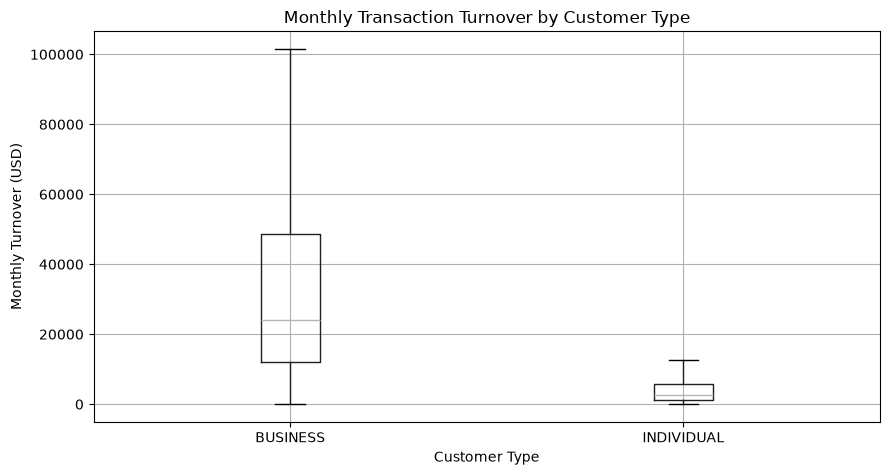

In [32]:

df.boxplot(
    column="amount_total_30d",
    by="customer_type",
    figsize=(9, 5),
    showfliers=False
)

plt.title("Monthly Transaction Turnover by Customer Type")
plt.suptitle("")
plt.xlabel("Customer Type")
plt.ylabel("Monthly Turnover (USD)")
plt.tight_layout()
plt.show()


Valid accounts: 2111
Median velocity: 0.0
95th percentile: 6.0
Maximum velocity: 30.0


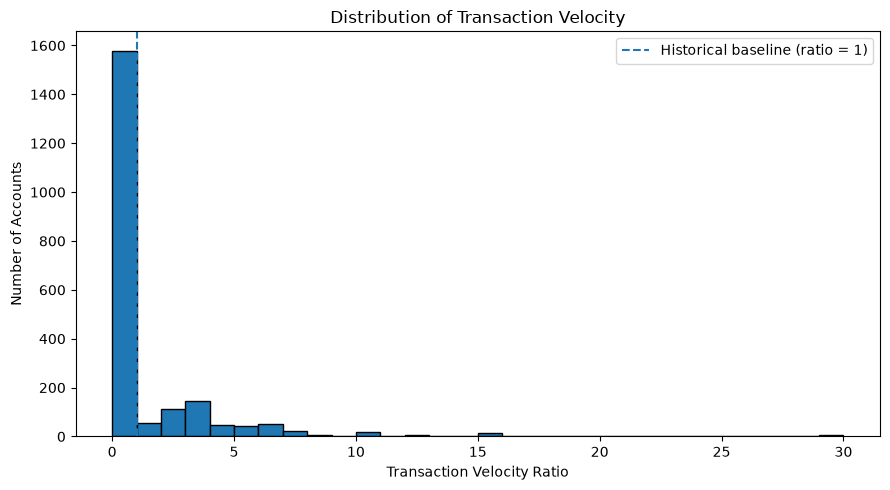

In [33]:

velocity = df["txn_velocity_ratio_24h_vs_prior30d"].dropna()

print("Valid accounts:", len(velocity))
print("Median velocity:", round(velocity.median(), 2))
print("95th percentile:", round(velocity.quantile(0.95), 2))
print("Maximum velocity:", round(velocity.max(), 2))

plt.figure(figsize=(9, 5))

plt.hist(velocity, bins=30, edgecolor="black")

plt.axvline(
    1,
    linestyle="--",
    label="Historical baseline (ratio = 1)"
)

plt.xlabel("Transaction Velocity Ratio")
plt.ylabel("Number of Accounts")
plt.title("Distribution of Transaction Velocity")

plt.legend()
plt.tight_layout()
plt.show()


Valid accounts: 1679
Median new counterparty share: 0.33
95th percentile: 1.0
Maximum share: 1.0


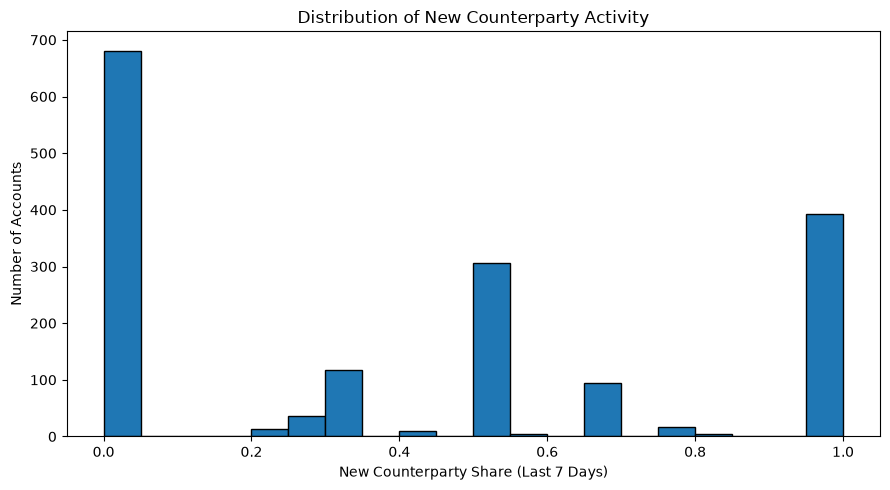

In [34]:

new_cp = df["new_counterparty_share_7d"].dropna()

print("Valid accounts:", len(new_cp))
print("Median new counterparty share:", round(new_cp.median(), 2))
print("95th percentile:", round(new_cp.quantile(0.95), 2))
print("Maximum share:", round(new_cp.max(), 2))

plt.figure(figsize=(9, 5))

plt.hist(new_cp, bins=20, edgecolor="black")

plt.xlabel("New Counterparty Share (Last 7 Days)")
plt.ylabel("Number of Accounts")
plt.title("Distribution of New Counterparty Activity")

plt.tight_layout()
plt.show()


Valid accounts: 2103
Median concentration: 0.41
95th percentile: 0.81
Maximum concentration: 1.0


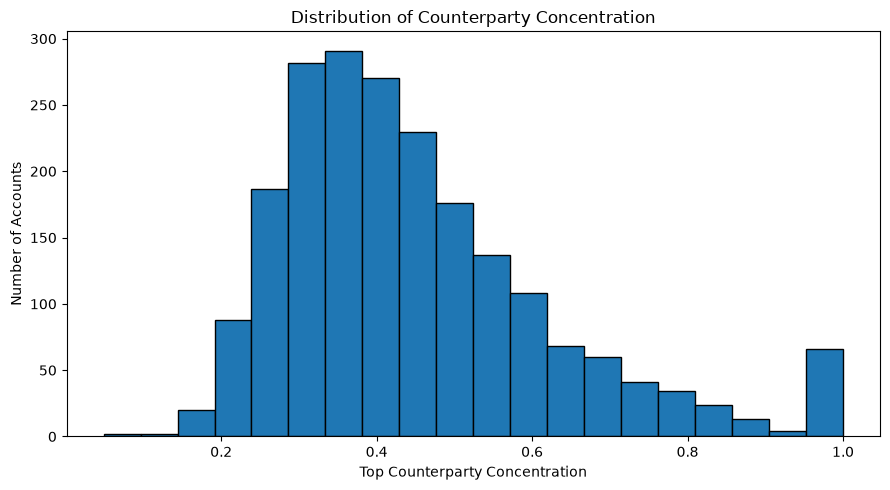

In [35]:

concentration = df["top_counterparty_concentration_30d"].dropna()

print("Valid accounts:", len(concentration))
print("Median concentration:", round(concentration.median(), 2))
print("95th percentile:", round(concentration.quantile(0.95), 2))
print("Maximum concentration:", round(concentration.max(), 2))

plt.figure(figsize=(9, 5))

plt.hist(concentration, bins=20, edgecolor="black")

plt.xlabel("Top Counterparty Concentration")
plt.ylabel("Number of Accounts")
plt.title("Distribution of Counterparty Concentration")

plt.tight_layout()
plt.show()


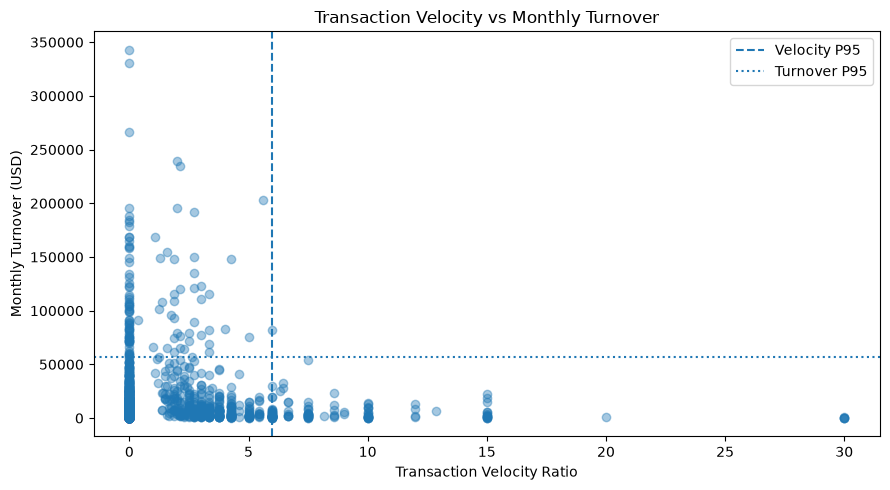

Accounts above both P95 benchmarks: 0


In [36]:

chart_df = df[
    ["txn_velocity_ratio_24h_vs_prior30d", "amount_total_30d"]
].dropna()

p95_velocity = chart_df["txn_velocity_ratio_24h_vs_prior30d"].quantile(0.95)
p95_turnover = df["amount_total_30d"].quantile(0.95)

plt.figure(figsize=(9, 5))

plt.scatter(
    chart_df["txn_velocity_ratio_24h_vs_prior30d"],
    chart_df["amount_total_30d"],
    alpha=0.4
)

plt.axvline(p95_velocity, linestyle="--", label="Velocity P95")
plt.axhline(p95_turnover, linestyle=":", label="Turnover P95")

plt.xlabel("Transaction Velocity Ratio")
plt.ylabel("Monthly Turnover (USD)")
plt.title("Transaction Velocity vs Monthly Turnover")

plt.legend()
plt.tight_layout()
plt.show()

high_both = (
    (chart_df["txn_velocity_ratio_24h_vs_prior30d"] > p95_velocity) &
    (chart_df["amount_total_30d"] > p95_turnover)
).sum()

print("Accounts above both P95 benchmarks:", high_both)


## 6. A few statistical checks

I use Spearman correlation to compare velocity and turnover, and Mann–Whitney U to compare groups. These tests describe this synthetic snapshot; they do not validate an AML detection system.

In [37]:

from scipy.stats import spearmanr

corr, p_value = spearmanr(
    chart_df["txn_velocity_ratio_24h_vs_prior30d"],
    chart_df["amount_total_30d"]
)

print("Spearman correlation:", round(corr, 4))
print("P-value:", round(p_value, 4))


Spearman correlation: 0.1025
P-value: 0.0


In [22]:

from scipy.stats import mannwhitneyu

business = df.loc[
    df["customer_type"] == "BUSINESS",
    "amount_total_30d"
]

individual = df.loc[
    df["customer_type"] == "INDIVIDUAL",
    "amount_total_30d"
]

stat, p_value = mannwhitneyu(
    business, individual, alternative="two-sided"
)

print("Business median:", round(business.median(), 2))
print("Individual median:", round(individual.median(), 2))
print("Mann-Whitney U:", round(stat, 2))
print("P-value:", f"{p_value:.3e}")


Business median: 24119.16
Individual median: 2732.18
Mann-Whitney U: 703223.0
P-value: 1.251e-167


In [23]:

n_business = len(business)
n_individual = len(individual)

effect_size = stat / (n_business * n_individual)

rank_biserial = 2 * effect_size - 1

print("Common-language effect size:", round(effect_size, 4))
print("Rank-biserial correlation:", round(rank_biserial, 4))


Common-language effect size: 0.9214
Rank-biserial correlation: 0.8429


In [25]:

customer_risk = (
    df.groupby("customer_id", as_index=False)
    .agg(
        high_turnover=("high_turnover_flag", "max"),
        expected_count_ratio=("expected_count_ratio_30d", "first")
    )
    .dropna(subset=["expected_count_ratio"])
)

flagged = customer_risk.loc[
    customer_risk["high_turnover"], "expected_count_ratio"
]

not_flagged = customer_risk.loc[
    ~customer_risk["high_turnover"], "expected_count_ratio"
]

stat, p_value = mannwhitneyu(
    flagged, not_flagged, alternative="two-sided"
)

print("Flagged customers:", len(flagged))
print("Other customers:", len(not_flagged))
print("Flagged median ratio:", round(flagged.median(), 2))
print("Other median ratio:", round(not_flagged.median(), 2))
print("P-value:", f"{p_value:.3e}")


Flagged customers: 101
Other customers: 1599
Flagged median ratio: 1.38
Other median ratio: 0.6
P-value: 1.812e-30


In [26]:

flagged_above = (flagged > 1).mean() * 100
other_above = (not_flagged > 1).mean() * 100

print("High-turnover customers above expected:", round(flagged_above, 2), "%")
print("Other customers above expected:", round(other_above, 2), "%")

print("Difference:", round(flagged_above - other_above, 2), "percentage points")


High-turnover customers above expected: 68.32 %
Other customers above expected: 19.89 %
Difference: 48.43 percentage points


## 7. Main observations and investigation notes

### Behavioural Risk Analysis – Key Findings

**Analysis Period:** September 2026  
**Snapshot Date:** 1 October 2026

#### 1. Transaction Behaviour by Customer Type

Business accounts generally showed higher transaction activity than individual accounts.

The median monthly turnover was $24,119 for business accounts and $2,732 for individual accounts. The statistical test also confirmed a significant difference between the two groups.

Based on this, using separate turnover benchmarks for business and individual customers makes more sense than applying the same threshold to everyone.

#### 2. High-Turnover Accounts

We identified 107 accounts belonging to 101 customers whose monthly turnover exceeded the 95th percentile of their respective customer groups.

These accounts are worth reviewing, but high turnover alone does not make them suspicious. Their activity needs to be checked against their expected turnover, transaction history and customer profile.

#### 3. Actual Activity vs Expected Activity

Among high-turnover customers, 68.32% performed more transactions than expected, compared with 19.89% of other customers.

This suggests that high turnover is often accompanied by higher-than-expected transaction frequency.

Checking both indicators together may help identify accounts that need closer attention.

#### 4. Transaction Velocity

The correlation between transaction velocity and monthly turnover was 0.1025, indicating a very weak positive relationship.

This means accounts with high monthly turnover do not necessarily experience sudden increases in transaction frequency.

Both features are useful to examine because they describe different aspects of account activity.

#### 5. Customer Review – C01598

Customer C01598 holds two accounts, A02005 and A02006.

During September, the customer recorded 26 transactions with a combined turnover of $343,934.10.

Total incoming funds were $124,782.50, while outgoing funds reached $219,151.60.

The customer's inflow was approximately 49.91 times the expected turnover, which stands out as a significant deviation from the recorded customer profile.

Most of the activity came from account A02005.

The next step would be to review the source and purpose of funds, transaction dates, counterparties and the customer's existing KYC information before deciding whether escalation is necessary.

#### 6. Overall Findings

The analysis shows that customer type, transaction turnover, expected activity and transaction velocity provide useful information when reviewing account behaviour.

Comparing customers with similar profiles helps identify unusual activity more fairly than using the same thresholds for everyone.

These findings provide a starting point for developing behavioural monitoring rules. However, the rules would still need testing against historical alerts and investigation outcomes before we could assess their effectiveness or recommend them for actual monitoring.

### Investigation Recommendations and Limitations

#### Recommended Next Steps

Based on the analysis, I would focus on customers whose transaction activity is unusually high compared with both their peer group and their expected profile.

I would start by reviewing the 101 high-turnover customers, particularly those whose transaction counts also exceed expectations.

For customer C01598, I would examine the individual transactions, source of funds, payment beneficiaries and available KYC records to understand why the activity differs so much from the expected profile.

I would also review accounts with sudden increases in transaction velocity or unusually high counterparty concentration. These indicators would need to be considered alongside transaction amounts and customer history.

#### Limitations

This analysis uses one monthly snapshot, so it does not show how customer behaviour changes over longer periods.

The 95th-percentile thresholds were used for exploration. They have not been tested as actual AML monitoring rules.

We also do not have confirmed suspicious-activity outcomes or false-positive results to measure how accurately these indicators identify financial crime.

Before recommending any rule changes, I would test the proposed indicators against historical transactions, review the resulting alerts and assess whether they provide useful information for investigators.

## 8. Build five explainable detection rules

The rules below use simple thresholds based on the September snapshot. Each rule creates a **candidate alert** with a reason an analyst can review. They have not been calibrated against confirmed case outcomes.

| Rule | Basic condition |
| --- | --- |
| High turnover and expected activity deviation | Turnover above customer-type P95 and transaction count above expected |
| Transaction velocity spike | Velocity ratio above P95 and at least 3 transactions in 24 hours |
| New counterparty activity | At least 80% new counterparties and at least 3 counterparties in 7 days |
| High cash amount and share | Cash amount and cash share both above P90 |
| Counterparty concentration | Concentration above P95 and at least 5 monthly transactions |

Review tiers are assigned only in the new-counterparty and concentration rules. Other alerts remain **Not specified**, not automatically low risk.

In [27]:

print("Total accounts:", len(df))
print("Unique accounts:", df["account_id"].nunique())
print("Snapshot dates:", df["snapshot_date"].nunique())

print("September transactions:", df["txn_count_30d"].sum())
print("September turnover:", round(df["amount_total_30d"].sum(), 2))

print("High-turnover accounts:", df["high_turnover_flag"].sum())

print(
    "High-turnover customers:",
    df.loc[df["high_turnover_flag"], "customer_id"].nunique()
)


Total accounts: 2135
Unique accounts: 2135
Snapshot dates: 1
September transactions: 18846
September turnover: 27315157.3
High-turnover accounts: 107
High-turnover customers: 101


### Rule 1 — High turnover and expected activity

In [28]:

rule_1 = customer_risk[
    (customer_risk["high_turnover"]) &
    (customer_risk["expected_count_ratio"] > 1)
].copy()

print("Candidate alerts:", len(rule_1))
print("Unique customers:", rule_1["customer_id"].nunique())

rule_1.head(10)


Candidate alerts: 69
Unique customers: 69


,customer_id,high_turnover,expected_count_ratio
29,C00030,True,1.8889
60,C00061,True,1.1000
97,C00098,True,3.2000
172,C00173,True,2.6667
197,C00198,True,1.2222
210,C00211,True,2.3333
214,C00215,True,1.4444
234,C00235,True,1.5000
273,C00274,True,2.1111
310,C00311,True,1.6429


In [30]:

rule_1["rule_name"] = "High Turnover and Expected Activity Deviation"

rule_1["alert_reason"] = (
    "Account turnover exceeded the peer-group 95th percentile. "
    "Customer transaction count was "
    + rule_1["expected_count_ratio"].round(2).astype(str)
    + " times the expected level."
)

rule_1[
    ["customer_id", "rule_name", "alert_reason"]
].head(10)


,customer_id,rule_name,alert_reason
29,C00030,High Turnover and Expected Activity Deviation,Account turnover exceeded the peer-group 95th ...
60,C00061,High Turnover and Expected Activity Deviation,Account turnover exceeded the peer-group 95th ...
97,C00098,High Turnover and Expected Activity Deviation,Account turnover exceeded the peer-group 95th ...
172,C00173,High Turnover and Expected Activity Deviation,Account turnover exceeded the peer-group 95th ...
197,C00198,High Turnover and Expected Activity Deviation,Account turnover exceeded the peer-group 95th ...
210,C00211,High Turnover and Expected Activity Deviation,Account turnover exceeded the peer-group 95th ...
214,C00215,High Turnover and Expected Activity Deviation,Account turnover exceeded the peer-group 95th ...
234,C00235,High Turnover and Expected Activity Deviation,Account turnover exceeded the peer-group 95th ...
273,C00274,High Turnover and Expected Activity Deviation,Account turnover exceeded the peer-group 95th ...
310,C00311,High Turnover and Expected Activity Deviation,Account turnover exceeded the peer-group 95th ...


In [31]:

print("Total alerts:", len(rule_1))

print("Duplicate customers:",
      rule_1["customer_id"].duplicated().sum())

print("Missing alert reasons:",
      rule_1["alert_reason"].isna().sum())

print("Blank alert reasons:",
      rule_1["alert_reason"].str.strip().eq("").sum())

print("Invalid rule conditions:",
      (
          (~rule_1["high_turnover"]) |
          (rule_1["expected_count_ratio"] <= 1)
      ).sum())


Total alerts: 69
Duplicate customers: 0
Missing alert reasons: 0
Blank alert reasons: 0
Invalid rule conditions: 0


### Rule 2 — Sudden transaction velocity

In [32]:

velocity_limit = df["txn_velocity_ratio_24h_vs_prior30d"].quantile(0.95)

velocity_alerts = df.loc[
    (df["txn_velocity_ratio_24h_vs_prior30d"] > velocity_limit) &
    (df["txn_count_24h"] >= 3),
    [
        "account_id",
        "customer_id",
        "customer_type",
        "txn_count_24h",
        "txn_count_30d",
        "txn_velocity_ratio_24h_vs_prior30d",
        "amount_total_24h"
    ]
].copy()

print("Velocity threshold:", round(velocity_limit, 2))
print("Candidate accounts:", len(velocity_alerts))
print("Unique customers:", velocity_alerts["customer_id"].nunique())

velocity_alerts.sort_values(
    "txn_velocity_ratio_24h_vs_prior30d",
    ascending=False
).head(10)


Velocity threshold: 6.0
Candidate accounts: 11
Unique customers: 11


,account_id,customer_id,customer_type,txn_count_24h,txn_count_30d,txn_velocity_ratio_24h_vs_prior30d,amount_total_24h
799,A00800,C00653,INDIVIDUAL,3,9,15.0000,2689.97
1010,A01011,C00819,INDIVIDUAL,3,9,15.0000,2649.60
1775,A01776,C01424,INDIVIDUAL,3,9,12.8571,1616.34
1527,A01528,C01227,INDIVIDUAL,3,12,10.0000,3548.99
2011,A02012,C01603,INDIVIDUAL,3,13,9.0000,1188.99
1653,A01654,C01325,INDIVIDUAL,3,13,9.0000,818.65
2053,A02054,C01633,INDIVIDUAL,3,13,8.1818,430.27
1253,A01254,C01013,BUSINESS,3,14,7.5000,3087.36
32,A00033,C00030,INDIVIDUAL,3,17,6.4286,1097.87
1933,A01934,C01544,BUSINESS,3,17,6.4286,8601.47


In [33]:

velocity_alerts["rule_name"] = "Sudden Transaction Velocity Spike"

velocity_alerts["alert_reason"] = (
    "Recorded "
    + velocity_alerts["txn_count_24h"].astype(str)
    + " transactions in 24 hours. Activity was "
    + velocity_alerts["txn_velocity_ratio_24h_vs_prior30d"].round(2).astype(str)
    + " times the historical daily rate."
)

velocity_alerts[
    ["account_id", "customer_id", "rule_name", "alert_reason"]
].head(10)


,account_id,customer_id,rule_name,alert_reason
32,A00033,C00030,Sudden Transaction Velocity Spike,Recorded 3 transactions in 24 hours. Activity ...
799,A00800,C00653,Sudden Transaction Velocity Spike,Recorded 3 transactions in 24 hours. Activity ...
1010,A01011,C00819,Sudden Transaction Velocity Spike,Recorded 3 transactions in 24 hours. Activity ...
1240,A01241,C01002,Sudden Transaction Velocity Spike,Recorded 4 transactions in 24 hours. Activity ...
1253,A01254,C01013,Sudden Transaction Velocity Spike,Recorded 3 transactions in 24 hours. Activity ...
1527,A01528,C01227,Sudden Transaction Velocity Spike,Recorded 3 transactions in 24 hours. Activity ...
1653,A01654,C01325,Sudden Transaction Velocity Spike,Recorded 3 transactions in 24 hours. Activity ...
1775,A01776,C01424,Sudden Transaction Velocity Spike,Recorded 3 transactions in 24 hours. Activity ...
1933,A01934,C01544,Sudden Transaction Velocity Spike,Recorded 3 transactions in 24 hours. Activity ...
2011,A02012,C01603,Sudden Transaction Velocity Spike,Recorded 3 transactions in 24 hours. Activity ...


In [34]:

print("Total alerts:", len(velocity_alerts))

print("Unique accounts:", velocity_alerts["account_id"].nunique())

print("Unique customers:", velocity_alerts["customer_id"].nunique())

print("Missing alert reasons:", velocity_alerts["alert_reason"].isna().sum())

print("Blank alert reasons:",
      velocity_alerts["alert_reason"].str.strip().eq("").sum())

invalid_alerts = (
    (velocity_alerts["txn_velocity_ratio_24h_vs_prior30d"] <= velocity_limit) |
    (velocity_alerts["txn_count_24h"] < 3)
).sum()

print("Invalid rule conditions:", invalid_alerts)

print("\nSample alert reason:")
print(velocity_alerts["alert_reason"].iloc[0])


Total alerts: 11
Unique accounts: 11
Unique customers: 11
Missing alert reasons: 0
Blank alert reasons: 0
Invalid rule conditions: 0

Sample alert reason:
Recorded 3 transactions in 24 hours. Activity was 6.43 times the historical daily rate.


### Rule 3 — New counterparties

In [35]:

counterparty_alerts = df.loc[
    (df["new_counterparty_share_7d"] >= 0.80) &
    (df["unique_counterparties_7d"] >= 3),
    [
        "account_id",
        "customer_id",
        "customer_type",
        "txn_count_7d",
        "unique_counterparties_7d",
        "new_counterparty_share_7d",
        "amount_total_7d"
    ]
].copy()

print("Candidate accounts:", len(counterparty_alerts))
print("Unique customers:", counterparty_alerts["customer_id"].nunique())

counterparty_alerts.sort_values(
    "new_counterparty_share_7d",
    ascending=False
).head(10)


Candidate accounts: 22
Unique customers: 22


,account_id,customer_id,customer_type,txn_count_7d,unique_counterparties_7d,new_counterparty_share_7d,amount_total_7d
69,A00070,C00062,INDIVIDUAL,3,3,1.0,4606.55
77,A00078,C00069,INDIVIDUAL,3,3,1.0,193.36
115,A00116,C00097,BUSINESS,3,3,1.0,2660.28
97,A00098,C00083,INDIVIDUAL,3,3,1.0,506.10
239,A00240,C00191,INDIVIDUAL,3,3,1.0,322.45
603,A00604,C00488,INDIVIDUAL,4,3,1.0,8730.53
1934,A01935,C01545,INDIVIDUAL,6,4,1.0,1299.55
652,A00653,C00534,BUSINESS,3,3,1.0,21613.48
855,A00856,C00695,INDIVIDUAL,3,3,1.0,2088.95
755,A00756,C00613,INDIVIDUAL,4,3,1.0,696.27


In [36]:

print("Total candidates:", len(counterparty_alerts))

print(
    "Accounts with 100% new counterparties:",
    (counterparty_alerts["new_counterparty_share_7d"] == 1).sum()
)

print(
    "Accounts with exactly 3 counterparties:",
    (counterparty_alerts["unique_counterparties_7d"] == 3).sum()
)

print(
    "Median 7-day turnover:",
    round(counterparty_alerts["amount_total_7d"].median(), 2)
)

print(
    "90th percentile turnover:",
    round(counterparty_alerts["amount_total_7d"].quantile(0.90), 2)
)


Total candidates: 22
Accounts with 100% new counterparties: 18
Accounts with exactly 3 counterparties: 16
Median 7-day turnover: 1864.28
90th percentile turnover: 9862.58


In [37]:

peer_p90_7d = df.groupby("customer_type")["amount_total_7d"].quantile(0.90)

counterparty_alerts["peer_p90_7d"] = (
    counterparty_alerts["customer_type"].map(peer_p90_7d)
)

counterparty_alerts["high_7d_turnover"] = (
    counterparty_alerts["amount_total_7d"] >
    counterparty_alerts["peer_p90_7d"]
)

print("Business P90:", round(peer_p90_7d["BUSINESS"], 2))
print("Individual P90:", round(peer_p90_7d["INDIVIDUAL"], 2))

print(
    "Candidates above peer P90:",
    counterparty_alerts["high_7d_turnover"].sum()
)

counterparty_alerts[
    [
        "account_id",
        "customer_type",
        "amount_total_7d",
        "peer_p90_7d",
        "high_7d_turnover"
    ]
].sort_values("amount_total_7d", ascending=False).head(10).round(2)


Business P90: 22882.73
Individual P90: 2698.1
Candidates above peer P90: 3


,account_id,customer_type,amount_total_7d,peer_p90_7d,high_7d_turnover
652,A00653,BUSINESS,21613.48,22882.73,False
680,A00681,BUSINESS,19414.29,22882.73,False
1489,A01490,BUSINESS,9988.36,22882.73,False
603,A00604,INDIVIDUAL,8730.53,2698.10,True
69,A00070,INDIVIDUAL,4606.55,2698.10,True
420,A00421,INDIVIDUAL,4116.74,2698.10,True
115,A00116,BUSINESS,2660.28,22882.73,False
1264,A01265,INDIVIDUAL,2585.73,2698.10,False
8,A00009,INDIVIDUAL,2169.12,2698.10,False
855,A00856,INDIVIDUAL,2088.95,2698.10,False


In [38]:

counterparty_alerts["rule_name"] = "Unusual New Counterparty Activity"

counterparty_alerts["review_tier"] = counterparty_alerts["high_7d_turnover"].map({
    True: "Enhanced review",
    False: "Initial review"
})

counterparty_alerts["alert_reason"] = (
    "In the last 7 days, "
    + (counterparty_alerts["new_counterparty_share_7d"] * 100).round(0).astype(int).astype(str)
    + "% of counterparties were new across "
    + counterparty_alerts["unique_counterparties_7d"].astype(str)
    + " unique counterparties."
)

print(counterparty_alerts["review_tier"].value_counts())

counterparty_alerts[
    ["account_id", "customer_id", "review_tier", "alert_reason"]
].head(10)


review_tier
Initial review     19
Enhanced review     3
Name: count, dtype: int64


,account_id,customer_id,review_tier,alert_reason
8,A00009,C00008,Initial review,"In the last 7 days, 80% of counterparties were..."
69,A00070,C00062,Enhanced review,"In the last 7 days, 100% of counterparties wer..."
77,A00078,C00069,Initial review,"In the last 7 days, 100% of counterparties wer..."
97,A00098,C00083,Initial review,"In the last 7 days, 100% of counterparties wer..."
115,A00116,C00097,Initial review,"In the last 7 days, 100% of counterparties wer..."
239,A00240,C00191,Initial review,"In the last 7 days, 100% of counterparties wer..."
420,A00421,C00341,Enhanced review,"In the last 7 days, 80% of counterparties were..."
603,A00604,C00488,Enhanced review,"In the last 7 days, 100% of counterparties wer..."
652,A00653,C00534,Initial review,"In the last 7 days, 100% of counterparties wer..."
680,A00681,C00556,Initial review,"In the last 7 days, 80% of counterparties were..."


In [39]:

print("Total alerts:", len(counterparty_alerts))

print("Unique accounts:",
      counterparty_alerts["account_id"].nunique())

print("Unique customers:",
      counterparty_alerts["customer_id"].nunique())

print("Missing alert reasons:",
      counterparty_alerts["alert_reason"].isna().sum())

print("Blank alert reasons:",
      counterparty_alerts["alert_reason"].str.strip().eq("").sum())

invalid_conditions = (
    (counterparty_alerts["new_counterparty_share_7d"] < 0.80) |
    (counterparty_alerts["unique_counterparties_7d"] < 3)
).sum()

print("Invalid rule conditions:", invalid_conditions)

invalid_tiers = (
    (counterparty_alerts["high_7d_turnover"] &
     (counterparty_alerts["review_tier"] != "Enhanced review")) |
    (~counterparty_alerts["high_7d_turnover"] &
     (counterparty_alerts["review_tier"] != "Initial review"))
).sum()

print("Incorrect review tiers:", invalid_tiers)


Total alerts: 22
Unique accounts: 22
Unique customers: 22
Missing alert reasons: 0
Blank alert reasons: 0
Invalid rule conditions: 0
Incorrect review tiers: 0


### Rule 4 — High cash amount and cash share

In [40]:

cash_cols = [
    "cash_amount_30d",
    "cash_amount_share_30d",
    "amount_total_30d"
]

cash_summary = df[cash_cols].describe(
    percentiles=[0.50, 0.90, 0.95, 0.99]
).T

print("Accounts with cash activity:", (df["cash_amount_30d"] > 0).sum())

cash_summary.round(2)


Accounts with cash activity: 1336


,count,mean,std,min,50%,90%,95%,99%,max
cash_amount_30d,2135.0,1442.23,4895.58,0.0,213.55,3346.71,5965.24,20738.95,133222.02
cash_amount_share_30d,2110.0,0.13,0.16,0.0,0.07,0.33,0.47,0.71,1.00
amount_total_30d,2135.0,12793.98,27939.01,0.0,3893.13,29153.64,57288.32,149552.89,342967.31


In [41]:

cash_limit = df["cash_amount_30d"].quantile(0.90)
share_limit = df["cash_amount_share_30d"].quantile(0.90)

cash_alerts = df.loc[
    (df["cash_amount_30d"] > cash_limit) &
    (df["cash_amount_share_30d"] > share_limit),
    [
        "account_id",
        "customer_id",
        "customer_type",
        "cash_amount_30d",
        "cash_amount_share_30d",
        "amount_total_30d"
    ]
].copy()

print("Cash amount threshold:", round(cash_limit, 2))
print("Cash share threshold:", round(share_limit, 2))

print("Candidate accounts:", len(cash_alerts))
print("Unique customers:", cash_alerts["customer_id"].nunique())

cash_alerts.sort_values(
    "cash_amount_30d", ascending=False
).head(10).round(2)


Cash amount threshold: 3346.71
Cash share threshold: 0.33
Candidate accounts: 50
Unique customers: 50


,account_id,customer_id,customer_type,cash_amount_30d,cash_amount_share_30d,amount_total_30d
116,A00117,C00098,INDIVIDUAL,133222.02,0.99,134567.19
1426,A01427,C01148,BUSINESS,63973.52,0.49,131026.09
720,A00721,C00585,BUSINESS,43818.23,1.00,43818.23
404,A00405,C00327,BUSINESS,33191.53,0.34,99068.99
271,A00272,C00216,BUSINESS,32384.64,0.47,68946.99
1552,A01553,C01248,BUSINESS,22419.78,0.65,34565.69
56,A00057,C00051,INDIVIDUAL,19956.27,0.79,25359.34
464,A00465,C00375,BUSINESS,15243.85,0.50,30632.66
227,A00228,C00181,BUSINESS,13906.72,0.35,40169.79
780,A00781,C00635,BUSINESS,12646.87,0.58,21751.39


In [42]:

cash_alerts["rule_name"] = "High Cash Amount and Cash Share"

cash_alerts["alert_reason"] = (
    "Monthly cash activity of "
    + cash_alerts["cash_amount_30d"].map(lambda x: f"${x:,.2f}")
    + " accounted for "
    + (cash_alerts["cash_amount_share_30d"] * 100).round(0).astype(int).astype(str)
    + "% of total turnover. Both cash activity thresholds were exceeded."
)

cash_alerts[
    ["account_id", "customer_id", "rule_name", "alert_reason"]
].head(10)


,account_id,customer_id,rule_name,alert_reason
30,A00031,C00028,High Cash Amount and Cash Share,"Monthly cash activity of $5,529.80 accounted f..."
40,A00041,C00037,High Cash Amount and Cash Share,"Monthly cash activity of $4,205.86 accounted f..."
56,A00057,C00051,High Cash Amount and Cash Share,"Monthly cash activity of $19,956.27 accounted ..."
84,A00085,C00075,High Cash Amount and Cash Share,"Monthly cash activity of $8,393.14 accounted f..."
115,A00116,C00097,High Cash Amount and Cash Share,"Monthly cash activity of $3,915.05 accounted f..."
116,A00117,C00098,High Cash Amount and Cash Share,"Monthly cash activity of $133,222.02 accounted..."
132,A00133,C00109,High Cash Amount and Cash Share,"Monthly cash activity of $8,638.59 accounted f..."
227,A00228,C00181,High Cash Amount and Cash Share,"Monthly cash activity of $13,906.72 accounted ..."
244,A00245,C00194,High Cash Amount and Cash Share,"Monthly cash activity of $4,527.22 accounted f..."
271,A00272,C00216,High Cash Amount and Cash Share,"Monthly cash activity of $32,384.64 accounted ..."


In [43]:

print("Total alerts:", len(cash_alerts))
print("Unique accounts:", cash_alerts["account_id"].nunique())
print("Unique customers:", cash_alerts["customer_id"].nunique())

print("Missing reasons:", cash_alerts["alert_reason"].isna().sum())

print("Blank reasons:",
      cash_alerts["alert_reason"].str.strip().eq("").sum())

invalid_conditions = (
    (cash_alerts["cash_amount_30d"] <= cash_limit) |
    (cash_alerts["cash_amount_share_30d"] <= share_limit)
).sum()

print("Invalid rule conditions:", invalid_conditions)


Total alerts: 50
Unique accounts: 50
Unique customers: 50
Missing reasons: 0
Blank reasons: 0
Invalid rule conditions: 0


### Rule 5 — Counterparty concentration

In [44]:

concentration_limit = df["top_counterparty_concentration_30d"].quantile(0.95)

concentration_alerts = df.loc[
    (df["top_counterparty_concentration_30d"] > concentration_limit) &
    (df["txn_count_30d"] >= 5),
    [
        "account_id",
        "customer_id",
        "customer_type",
        "txn_count_30d",
        "unique_counterparties_30d",
        "top_counterparty_concentration_30d",
        "amount_total_30d"
    ]
].copy()

print("Concentration threshold:", round(concentration_limit, 2))
print("Candidate accounts:", len(concentration_alerts))
print("Unique customers:", concentration_alerts["customer_id"].nunique())

concentration_alerts.sort_values(
    "top_counterparty_concentration_30d",
    ascending=False
).head(10)


Concentration threshold: 0.81
Candidate accounts: 16
Unique customers: 16


,account_id,customer_id,customer_type,txn_count_30d,unique_counterparties_30d,top_counterparty_concentration_30d,amount_total_30d
419,A00420,C00340,INDIVIDUAL,5,1,1.0000,878.07
2036,A02037,C01621,INDIVIDUAL,5,1,1.0000,802.60
1467,A01468,C01179,INDIVIDUAL,7,2,0.9139,1662.34
561,A00562,C00456,INDIVIDUAL,7,2,0.8829,825.56
1947,A01948,C01554,INDIVIDUAL,6,2,0.8778,29236.79
1765,A01766,C01415,INDIVIDUAL,5,2,0.8676,1540.11
410,A00411,C00332,INDIVIDUAL,5,2,0.8642,2084.53
29,A00030,C00027,INDIVIDUAL,5,2,0.8585,532.60
524,A00525,C00425,INDIVIDUAL,5,2,0.8564,4588.19
397,A00398,C00320,INDIVIDUAL,6,3,0.8399,3913.47


In [45]:

print(
    "Accounts with 1 counterparty:",
    (concentration_alerts["unique_counterparties_30d"] == 1).sum()
)

print(
    "Accounts with 2 or fewer counterparties:",
    (concentration_alerts["unique_counterparties_30d"] <= 2).sum()
)

print(
    "Accounts with exactly 5 transactions:",
    (concentration_alerts["txn_count_30d"] == 5).sum()
)

print(
    "Median monthly turnover:",
    round(concentration_alerts["amount_total_30d"].median(), 2)
)

print(
    "Business accounts:",
    (concentration_alerts["customer_type"] == "BUSINESS").sum()
)


Accounts with 1 counterparty: 2
Accounts with 2 or fewer counterparties: 11
Accounts with exactly 5 transactions: 7
Median monthly turnover: 2012.8
Business accounts: 1


In [46]:

peer_p90_30d = df.groupby("customer_type")["amount_total_30d"].quantile(0.90)

concentration_alerts["peer_p90_30d"] = (
    concentration_alerts["customer_type"].map(peer_p90_30d)
)

concentration_alerts["high_peer_turnover"] = (
    concentration_alerts["amount_total_30d"] >
    concentration_alerts["peer_p90_30d"]
)

print("Business P90:", round(peer_p90_30d["BUSINESS"], 2))
print("Individual P90:", round(peer_p90_30d["INDIVIDUAL"], 2))

print(
    "Candidates above peer P90:",
    concentration_alerts["high_peer_turnover"].sum()
)

concentration_alerts[
    [
        "account_id",
        "customer_type",
        "top_counterparty_concentration_30d",
        "amount_total_30d",
        "peer_p90_30d",
        "high_peer_turnover"
    ]
].sort_values("amount_total_30d", ascending=False).head(10).round(2)


Business P90: 99670.88
Individual P90: 10925.5
Candidates above peer P90: 2


,account_id,customer_type,top_counterparty_concentration_30d,amount_total_30d,peer_p90_30d,high_peer_turnover
1947,A01948,INDIVIDUAL,0.88,29236.79,10925.50,True
948,A00949,INDIVIDUAL,0.82,25117.13,10925.50,True
1200,A01201,INDIVIDUAL,0.84,8728.55,10925.50,False
809,A00810,BUSINESS,0.83,6061.05,99670.88,False
524,A00525,INDIVIDUAL,0.86,4588.19,10925.50,False
397,A00398,INDIVIDUAL,0.84,3913.47,10925.50,False
1622,A01623,INDIVIDUAL,0.82,2309.30,10925.50,False
410,A00411,INDIVIDUAL,0.86,2084.53,10925.50,False
1147,A01148,INDIVIDUAL,0.82,1941.08,10925.50,False
1467,A01468,INDIVIDUAL,0.91,1662.34,10925.50,False


In [47]:

concentration_alerts["rule_name"] = "High Counterparty Concentration"

concentration_alerts["review_tier"] = np.where(
    concentration_alerts["high_peer_turnover"],
    "Enhanced review",
    "Initial review"
)

concentration_alerts["alert_reason"] = (
    "Top counterparty accounted for "
    + (concentration_alerts["top_counterparty_concentration_30d"] * 100).round(1).astype(str)
    + "% of measured monthly activity across "
    + concentration_alerts["txn_count_30d"].astype(str)
    + " transactions involving "
    + concentration_alerts["unique_counterparties_30d"].astype(str)
    + " unique counterparties."
)

print(concentration_alerts["review_tier"].value_counts())

concentration_alerts[
    ["account_id", "customer_id", "review_tier", "alert_reason"]
].head(10)


review_tier
Initial review     14
Enhanced review     2
Name: count, dtype: int64


,account_id,customer_id,review_tier,alert_reason
29,A00030,C00027,Initial review,Top counterparty accounted for 85.9% of measur...
397,A00398,C00320,Initial review,Top counterparty accounted for 84.0% of measur...
410,A00411,C00332,Initial review,Top counterparty accounted for 86.4% of measur...
419,A00420,C00340,Initial review,Top counterparty accounted for 100.0% of measu...
524,A00525,C00425,Initial review,Top counterparty accounted for 85.6% of measur...
561,A00562,C00456,Initial review,Top counterparty accounted for 88.3% of measur...
809,A00810,C00659,Initial review,Top counterparty accounted for 83.0% of measur...
850,A00851,C00691,Initial review,Top counterparty accounted for 81.7% of measur...
948,A00949,C00770,Enhanced review,Top counterparty accounted for 82.1% of measur...
1147,A01148,C00927,Initial review,Top counterparty accounted for 81.8% of measur...


In [48]:

print("Total alerts:", len(concentration_alerts))
print("Unique accounts:", concentration_alerts["account_id"].nunique())
print("Unique customers:", concentration_alerts["customer_id"].nunique())

print("Missing reasons:", concentration_alerts["alert_reason"].isna().sum())

print("Blank reasons:",
      concentration_alerts["alert_reason"].str.strip().eq("").sum())

invalid_conditions = (
    (concentration_alerts["top_counterparty_concentration_30d"] <= concentration_limit) |
    (concentration_alerts["txn_count_30d"] < 5)
).sum()

print("Invalid rule conditions:", invalid_conditions)

invalid_tiers = (
    (concentration_alerts["high_peer_turnover"] &
     (concentration_alerts["review_tier"] != "Enhanced review")) |
    (~concentration_alerts["high_peer_turnover"] &
     (concentration_alerts["review_tier"] != "Initial review"))
).sum()

print("Incorrect review tiers:", invalid_tiers)


Total alerts: 16
Unique accounts: 16
Unique customers: 16
Missing reasons: 0
Blank reasons: 0
Invalid rule conditions: 0
Incorrect review tiers: 0


## 9. Combine alerts and prepare the customer queue

The turnover rule works at **customer level**. The other four rules work at **account level**. I keep that difference in `alert_level` and count distinct rules per customer for the review queue.

In [49]:
# Combine the five rule results into one alert list.
cols = [
    "customer_id", "account_id", "rule_name", "alert_reason",
    "alert_level", "review_tier"
]

r1 = rule_1[["customer_id", "rule_name", "alert_reason"]].copy()
r1["account_id"] = pd.NA
r1["alert_level"] = "CUSTOMER"
r1["review_tier"] = pd.NA

r2 = velocity_alerts.assign(alert_level="ACCOUNT", review_tier=pd.NA)
r3 = counterparty_alerts.assign(alert_level="ACCOUNT")
r4 = cash_alerts.assign(alert_level="ACCOUNT", review_tier=pd.NA)
r5 = concentration_alerts.assign(alert_level="ACCOUNT")

all_alerts = pd.concat(
    [r1[cols], r2[cols], r3[cols], r4[cols], r5[cols]],
    ignore_index=True
)

print("Total rule triggers:", len(all_alerts))
print("Unique customers:", all_alerts["customer_id"].nunique())
print("Missing customer IDs:", all_alerts["customer_id"].isna().sum())

all_alerts.groupby("rule_name").size()

Total rule triggers: 168
Unique customers: 157
Missing customer IDs: 0


rule_name
High Cash Amount and Cash Share                  50
High Counterparty Concentration                  16
High Turnover and Expected Activity Deviation    69
Sudden Transaction Velocity Spike                11
Unusual New Counterparty Activity                22
dtype: int64

In [50]:

print("Total rule triggers:", len(all_alerts))
print("Unique customers:", all_alerts["customer_id"].nunique())
print("Missing customer IDs:", all_alerts["customer_id"].isna().sum())

customer_triggers = (
    all_alerts.groupby("customer_id")["rule_name"]
    .nunique()
)

print("Customers triggering multiple rules:",
      (customer_triggers > 1).sum())

print("Maximum rules triggered by one customer:",
      customer_triggers.max())


Total rule triggers: 168
Unique customers: 157
Missing customer IDs: 0
Customers triggering multiple rules: 10
Maximum rules triggered by one customer: 3


In [51]:

multi_ids = customer_triggers[customer_triggers > 1].index

overlap = all_alerts[
    all_alerts["customer_id"].isin(multi_ids)
].sort_values(["customer_id", "rule_name"])

print("Customers with multiple rules:", len(multi_ids))

print(
    overlap[
        ["customer_id", "account_id", "rule_name", "alert_level"]
    ].to_string(index=False)
)


Customers with multiple rules: 10
customer_id account_id                                     rule_name alert_level
     C00030       <NA> High Turnover and Expected Activity Deviation    CUSTOMER
     C00030     A00033             Sudden Transaction Velocity Spike     ACCOUNT
     C00097     A00116               High Cash Amount and Cash Share     ACCOUNT
     C00097     A00116             Unusual New Counterparty Activity     ACCOUNT
     C00098     A00117               High Cash Amount and Cash Share     ACCOUNT
     C00098       <NA> High Turnover and Expected Activity Deviation    CUSTOMER
     C00399     A00494               High Cash Amount and Cash Share     ACCOUNT
     C00399       <NA> High Turnover and Expected Activity Deviation    CUSTOMER
     C00705     A00868               High Cash Amount and Cash Share     ACCOUNT
     C00705       <NA> High Turnover and Expected Activity Deviation    CUSTOMER
     C00714     A00879               High Cash Amount and Cash Share     AC

In [52]:

customer_alert_summary = (
    all_alerts.groupby("customer_id")
    .agg(
        rule_count=("rule_name", "nunique"),
        triggered_accounts=("account_id", "nunique")
    )
    .reset_index()
)

customer_alert_summary["review_queue"] = np.where(
    customer_alert_summary["rule_count"] > 1,
    "Multi-rule review",
    "Single-rule review"
)

print(customer_alert_summary["review_queue"].value_counts())

customer_alert_summary.sort_values(
    ["rule_count", "customer_id"],
    ascending=[False, True]
).head(10)


review_queue
Single-rule review    147
Multi-rule review      10
Name: count, dtype: int64


,customer_id,rule_count,triggered_accounts,review_queue
74,C00819,3,2,Multi-rule review
3,C00030,2,1,Multi-rule review
11,C00097,2,1,Multi-rule review
12,C00098,2,1,Multi-rule review
38,C00399,2,1,Multi-rule review
65,C00705,2,1,Multi-rule review
66,C00714,2,1,Multi-rule review
71,C00770,2,1,Multi-rule review
89,C01002,2,1,Multi-rule review
138,C01554,2,1,Multi-rule review


In [53]:

customer_rules = (
    all_alerts.groupby("customer_id")["rule_name"]
    .agg(lambda x: " | ".join(sorted(x.unique())))
)

customer_alert_summary["triggered_rules"] = (
    customer_alert_summary["customer_id"].map(customer_rules)
)

print("Total customers:", len(customer_alert_summary))
print("Missing rule summaries:", customer_alert_summary["triggered_rules"].isna().sum())

customer_alert_summary.sort_values(
    ["rule_count", "customer_id"],
    ascending=[False, True]
).head(10)


Total customers: 157
Missing rule summaries: 0


,customer_id,rule_count,triggered_accounts,review_queue,triggered_rules
74,C00819,3,2,Multi-rule review,High Cash Amount and Cash Share | High Turnove...
3,C00030,2,1,Multi-rule review,High Turnover and Expected Activity Deviation ...
11,C00097,2,1,Multi-rule review,High Cash Amount and Cash Share | Unusual New ...
12,C00098,2,1,Multi-rule review,High Cash Amount and Cash Share | High Turnove...
38,C00399,2,1,Multi-rule review,High Cash Amount and Cash Share | High Turnove...
65,C00705,2,1,Multi-rule review,High Cash Amount and Cash Share | High Turnove...
66,C00714,2,1,Multi-rule review,High Cash Amount and Cash Share | High Turnove...
71,C00770,2,1,Multi-rule review,High Counterparty Concentration | High Turnove...
89,C01002,2,1,Multi-rule review,High Turnover and Expected Activity Deviation ...
138,C01554,2,1,Multi-rule review,High Counterparty Concentration | High Turnove...


In [54]:
# Some rules have no review tier assigned.
print("Total rule triggers:", len(all_alerts))
print(all_alerts["review_tier"].fillna("Not specified").value_counts())

Total rule triggers: 168
review_tier
Not specified      130
Initial review      33
Enhanced review      5
Name: count, dtype: int64


In [55]:

all_alerts["alert_id"] = [
    f"ALT{i:06d}" for i in range(1, len(all_alerts) + 1)
]

all_alerts["snapshot_date"] = df["snapshot_date"].iloc[0]

all_alerts = all_alerts[
    ["alert_id", "snapshot_date"] + cols
]

print("Total alerts:", len(all_alerts))
print("Unique alert IDs:", all_alerts["alert_id"].nunique())
print("Snapshot dates:", all_alerts["snapshot_date"].nunique())

all_alerts.head(10)


Total alerts: 168
Unique alert IDs: 168
Snapshot dates: 1


,alert_id,snapshot_date,customer_id,account_id,rule_name,alert_reason,alert_level,review_tier
0,ALT000001,2026-10-01,C00030,<NA>,High Turnover and Expected Activity Deviation,Account turnover exceeded the peer-group 95th ...,CUSTOMER,<NA>
1,ALT000002,2026-10-01,C00061,<NA>,High Turnover and Expected Activity Deviation,Account turnover exceeded the peer-group 95th ...,CUSTOMER,<NA>
2,ALT000003,2026-10-01,C00098,<NA>,High Turnover and Expected Activity Deviation,Account turnover exceeded the peer-group 95th ...,CUSTOMER,<NA>
3,ALT000004,2026-10-01,C00173,<NA>,High Turnover and Expected Activity Deviation,Account turnover exceeded the peer-group 95th ...,CUSTOMER,<NA>
4,ALT000005,2026-10-01,C00198,<NA>,High Turnover and Expected Activity Deviation,Account turnover exceeded the peer-group 95th ...,CUSTOMER,<NA>
5,ALT000006,2026-10-01,C00211,<NA>,High Turnover and Expected Activity Deviation,Account turnover exceeded the peer-group 95th ...,CUSTOMER,<NA>
6,ALT000007,2026-10-01,C00215,<NA>,High Turnover and Expected Activity Deviation,Account turnover exceeded the peer-group 95th ...,CUSTOMER,<NA>
7,ALT000008,2026-10-01,C00235,<NA>,High Turnover and Expected Activity Deviation,Account turnover exceeded the peer-group 95th ...,CUSTOMER,<NA>
8,ALT000009,2026-10-01,C00274,<NA>,High Turnover and Expected Activity Deviation,Account turnover exceeded the peer-group 95th ...,CUSTOMER,<NA>
9,ALT000010,2026-10-01,C00311,<NA>,High Turnover and Expected Activity Deviation,Account turnover exceeded the peer-group 95th ...,CUSTOMER,<NA>


In [56]:

print("Total alerts:", len(all_alerts))

print("Duplicate alert IDs:",
      all_alerts["alert_id"].duplicated().sum())

print("Missing customer IDs:",
      all_alerts["customer_id"].isna().sum())

print("Missing rule names:",
      all_alerts["rule_name"].isna().sum())

print("Missing or blank reasons:",
      (all_alerts["alert_reason"].isna() |
       all_alerts["alert_reason"].str.strip().eq("")).sum())

invalid_accounts = (
    ((all_alerts["alert_level"] == "ACCOUNT") &
     all_alerts["account_id"].isna()) |
    ((all_alerts["alert_level"] == "CUSTOMER") &
     all_alerts["account_id"].notna())
).sum()

print("Invalid account assignments:", invalid_accounts)

print("Invalid alert levels:",
      (~all_alerts["alert_level"].isin(["ACCOUNT", "CUSTOMER"])).sum())

print("Duplicate rule triggers:",
      all_alerts.duplicated(
          subset=["snapshot_date", "customer_id", "account_id", "rule_name"]
      ).sum())

print("\nAlerts by level:")
print(all_alerts["alert_level"].value_counts())


Total alerts: 168
Duplicate alert IDs: 0
Missing customer IDs: 0
Missing rule names: 0
Missing or blank reasons: 0
Invalid account assignments: 0
Invalid alert levels: 0
Duplicate rule triggers: 0

Alerts by level:
alert_level
ACCOUNT     99
CUSTOMER    69
Name: count, dtype: int64


## 10. Export the Tableau datasets

I save three CSV files in `notebooks/outputs`: account features, individual alerts and a customer-level investigation queue. The original transaction and feature SQL scripts are separate from this notebook.

In [57]:
from pathlib import Path

# Save the Tableau files inside the project, not a personal Windows path.
project_folder = Path.cwd()

if project_folder.name == "notebooks":
    output_dir = project_folder / "outputs"
else:
    output_dir = project_folder / "notebooks" / "outputs"

output_dir.mkdir(parents=True, exist_ok=True)

all_alerts.to_csv(output_dir / "alerts.csv", index=False)

customer_queue = customer_alert_summary.copy()
customer_queue["snapshot_date"] = df["snapshot_date"].iloc[0]
customer_queue.to_csv(output_dir / "customer_queue.csv", index=False)

print("Alerts exported:", len(all_alerts))
print("Customer queue exported:", len(customer_queue))
print("Saved the CSVs in the notebooks/outputs folder.")

Alerts exported: 168
Customer queue exported: 157
Saved the CSVs in the notebooks/outputs folder.


In [58]:
# Keep the account features used by the Tableau dashboards.
feature_file = output_dir / "account_features.csv"
df.to_csv(feature_file, index=False)

check_df = pd.read_csv(feature_file)
print("Exported accounts:", len(check_df))
print("Unique accounts:", check_df["account_id"].nunique())
print("Columns:", len(check_df.columns))

Exported accounts: 2135
Unique accounts: 2135
Columns: 53


## 11. Check the exported files

These final checks make sure the Tableau files agree on account counts, rule triggers and flagged customers. I also check for duplicate IDs and explain missing ratios.

In [59]:
# Read back the three CSVs saved for Tableau.
accounts = pd.read_csv(output_dir / "account_features.csv")
alerts = pd.read_csv(output_dir / "alerts.csv")
queue = pd.read_csv(output_dir / "customer_queue.csv")

# Check the main record counts.
print("Accounts:", len(accounts))
print("September transactions:", accounts["txn_count_30d"].sum())
print("September turnover:", round(accounts["amount_total_30d"].sum(), 2))
print("Alert records:", len(alerts))
print("Unique alert IDs:", alerts["alert_id"].nunique())
print("Unique flagged customers:", alerts["customer_id"].nunique())
print("Customers in queue:", len(queue))
print("Multi-rule customers:", (queue["rule_count"] > 1).sum())


Accounts: 2135
September transactions: 18846
September turnover: 27315157.3
Alert records: 168
Unique alert IDs: 168
Unique flagged customers: 157
Customers in queue: 157
Multi-rule customers: 10


In [60]:

# Check how many alerts each detection rule generated.
rule_counts = (
    alerts.groupby("rule_name")["alert_id"]
    .nunique()
    .sort_values(ascending=False)
)

print("ALERTS BY DETECTION RULE")
print(rule_counts.to_string())

# Check how many customers triggered 1, 2 or 3 rules.
print("\nRULE COUNT DISTRIBUTION")
print(queue["rule_count"].value_counts().sort_index().to_string())

# Recalculate each customer's rule count from alerts.
actual_rules = (
    alerts.groupby("customer_id")["rule_name"]
    .nunique()
    .rename("actual_rule_count")
)

# Compare calculated counts against the customer queue.
comparison = queue[["customer_id", "rule_count"]].merge(
    actual_rules,
    on="customer_id",
    how="outer",
    indicator=True
)

mismatches = comparison[
    (comparison["_merge"] != "both") |
    (comparison["rule_count"] != comparison["actual_rule_count"])
]

print("\nINTEGRITY CHECKS")
print("Detection rules:", len(rule_counts))
print("Total rule triggers:", rule_counts.sum())
print("Duplicate queue customers:", queue["customer_id"].duplicated().sum())
print("Rule count mismatches:", len(mismatches))


ALERTS BY DETECTION RULE
rule_name
High Turnover and Expected Activity Deviation    69
High Cash Amount and Cash Share                  50
Unusual New Counterparty Activity                22
High Counterparty Concentration                  16
Sudden Transaction Velocity Spike                11

RULE COUNT DISTRIBUTION
rule_count
1    147
2      9
3      1

INTEGRITY CHECKS
Detection rules: 5
Total rule triggers: 168
Duplicate queue customers: 0
Rule count mismatches: 0


In [61]:

# Check for duplicate IDs and missing identifiers.
print("RECORD INTEGRITY")
print("Duplicate account IDs:", accounts["account_id"].duplicated().sum())
print("Duplicate alert IDs:", alerts["alert_id"].duplicated().sum())
print("Duplicate queue customer IDs:", queue["customer_id"].duplicated().sum())

print("\nMISSING IDENTIFIERS")
print("Missing account IDs:", accounts["account_id"].isna().sum())
print("Missing alert IDs:", alerts["alert_id"].isna().sum())
print("Missing alert customer IDs:", alerts["customer_id"].isna().sum())
print("Missing queue customer IDs:", queue["customer_id"].isna().sum())

# Make sure both investigation outputs contain the same customers.
alert_customers = set(alerts["customer_id"].dropna())
queue_customers = set(queue["customer_id"].dropna())

print("\nCUSTOMER RECONCILIATION")
print("Alert customers missing from queue:", len(alert_customers - queue_customers))
print("Queue customers missing from alerts:", len(queue_customers - alert_customers))

# Negative counts or turnover would need investigation.
print("\nTRANSACTION VALUE CHECKS")
print("Negative transaction counts:", (accounts["txn_count_30d"] < 0).sum())
print("Negative monthly turnover:", (accounts["amount_total_30d"] < 0).sum())

# Review tiers can be missing; we already investigated their meaning.
print("\nREVIEW TIER DISTRIBUTION")
print(alerts["review_tier"].fillna("Not specified").value_counts().to_string())


RECORD INTEGRITY
Duplicate account IDs: 0
Duplicate alert IDs: 0
Duplicate queue customer IDs: 0

MISSING IDENTIFIERS
Missing account IDs: 0
Missing alert IDs: 0
Missing alert customer IDs: 0
Missing queue customer IDs: 0

CUSTOMER RECONCILIATION
Alert customers missing from queue: 0
Queue customers missing from alerts: 0

TRANSACTION VALUE CHECKS
Negative transaction counts: 0
Negative monthly turnover: 0

REVIEW TIER DISTRIBUTION
review_tier
Not specified      130
Initial review      33
Enhanced review      5


In [62]:
# Check why two feature ratios have missing values.
cash_null = accounts["cash_amount_share_30d"].isna()
cp_null = accounts["new_counterparty_share_7d"].isna()

print("CASH SHARE CHECK")
print("NULL cash share:", cash_null.sum())
print("NULL with zero turnover:", (cash_null & (accounts["amount_total_30d"] == 0)).sum())
print("NULL with positive turnover:", (cash_null & (accounts["amount_total_30d"] > 0)).sum())

print("\nCOUNTERPARTY SHARE CHECK")
print("NULL new counterparty share:", cp_null.sum())
print("NULL with zero recent counterparties:", (cp_null & (accounts["unique_counterparties_7d"] == 0)).sum())
print("NULL despite recent counterparties:", (cp_null & (accounts["unique_counterparties_7d"] > 0)).sum())

CASH SHARE CHECK
NULL cash share: 25
NULL with zero turnover: 25
NULL with positive turnover: 0

COUNTERPARTY SHARE CHECK
NULL new counterparty share: 456
NULL with zero recent counterparties: 456
NULL despite recent counterparties: 0


## 12. What the results mean

- **2,135 accounts** and **18,846 September transactions** were included in the feature snapshot.
- The five rules produced **168 triggers across 157 customers**. Ten customers triggered more than one rule.
- **130 alerts have no assigned review tier.** This means *Not specified*, not *cleared* or *low risk*.
- **25 cash-share ratios** are undefined because monthly turnover was zero. **456 new-counterparty-share ratios** are undefined because there were no counterparties in the last seven days.
- The data is synthetic and covers a single snapshot. We have no labelled suspicious cases, investigation outcomes or false-positive results, so I cannot claim precision, recall or real-world detection performance.

**Next analyst step:** Review the customer profile, source and purpose of funds, transaction history and counterparties before deciding whether any alert needs escalation. The Tableau dashboards help explore these candidate alerts.